# Test 1: mejora del prompt y de sus instrucciones

Cinco iteraciones sobre un agente de negociación sintética, con escenarios, prompts y system prompts en español. Se cambia el prompt, se evalúa y se decide si se conserva. También se actualizan las instrucciones que guían la siguiente propuesta.

[Variables y matriz](https://github.com/jairzinhosantos/thinking-harness/blob/develop/docs/academic/README.md) · [Código](https://github.com/jairzinhosantos/thinking-harness/blob/develop/research/cases/case-0003-debt-negotiation/utils/harness_smoke_test.py)

## 1. Abrir o ejecutar

Las salidas provienen de una ejecución real de API. Por defecto, `RUN_LIVE = False` lee esa evidencia sin hacer nuevas llamadas.

Para repetir: Python 3.11+, instalar `pip install -r requirements.txt`, seleccionar ese entorno como kernel, configurar `OPENAI_API_KEY` en el `.env` local y activar `RUN_LIVE`. No escribir la clave en una celda. La nueva ejecución se guarda en `runs/`.

In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display, Markdown, HTML

LANGUAGE = 'es'
RUN_LIVE = False
CASE = next((p / 'research/cases/case-0003-debt-negotiation'
             for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'research/cases/case-0003-debt-negotiation').is_dir()), None)
if CASE is None:
    raise RuntimeError('Open the notebook from this repository')
sys.path.insert(0, str(CASE / 'utils'))
from harness_smoke_test import run, load_run, summarize
from prompt_search import rule_check

RUN_DIR = CASE / 'results/20261031T014753Z-smoke-ef430d08'
if RUN_LIVE:
    from dotenv import load_dotenv
    load_dotenv(CASE / '.env', override=False)
    RUN_DIR = run()
protocol, report = load_run(RUN_DIR)
calls = [json.loads(line) for line in (RUN_DIR / 'calls.jsonl').read_text().splitlines()]

from notebook_view import HarnessTestView, audit_harness_changes
view = HarnessTestView()
table = view.rows

table(['Registro', 'Valor'], [
    ['Protocolo', report['protocol']], ['Ejecución', report['run_id']],
    ['Estado', 'Completada' if report['status'] == 'completed' else 'Detenida'],
    ['Modo', 'API nueva' if RUN_LIVE else 'Lectura de evidencia guardada'],
])

Registro,Valor
Protocolo,case-0003-harness-smoke-v3
Ejecución,20261031T014753Z-smoke-ef430d08
Estado,Completada
Modo,Lectura de evidencia guardada


## 2. Qué cambia

| Parte | Variable | Cambio permitido |
|---|---|---|
| Política dentro del system prompt del negociador | $H_t$ | Una candidata por iteración; se conserva si supera el filtro |
| Instrucciones dentro del system prompt del mejorador | $\phi_t$ | Se reemplazan tras las propuestas 1 a 4 |
| Régimen | $Z=1$, B2 | Se permite adaptar las instrucciones; B1 las mantendría fijas |
| Modelo, contratos fijos, reglas, datos y motor | Controles | Permanecen fijos |

El LLM propone; Python evalúa y selecciona. Aquí se modifican textos del harness, sin agregar agentes ni herramientas. H0, H1, etc. identifican versiones y candidatas; una candidata rechazada no se convierte en la política vigente.


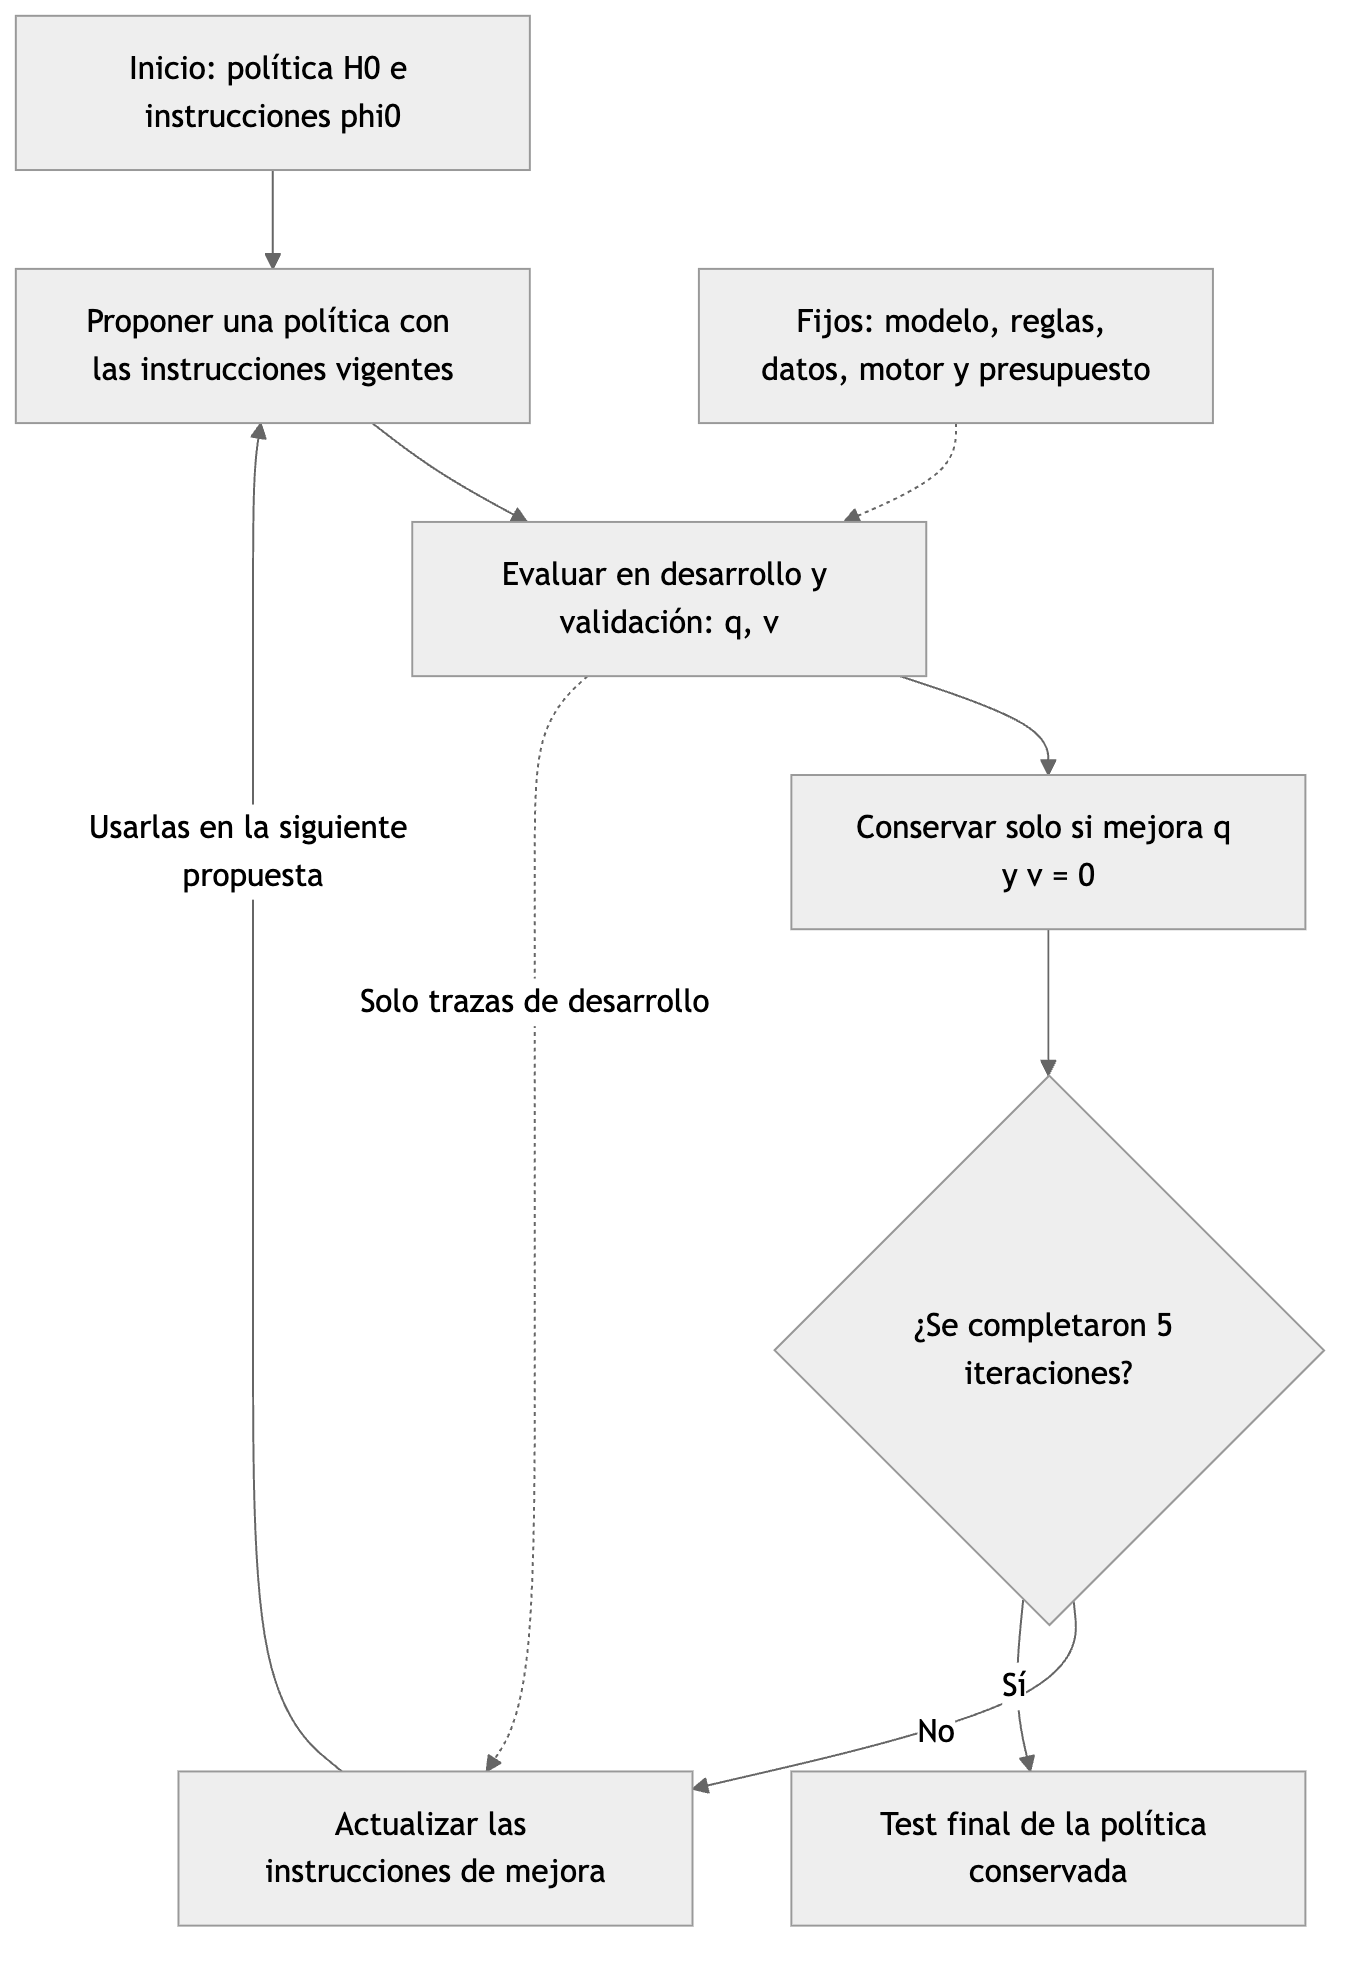

[Fuente del diagrama](https://github.com/jairzinhosantos/thinking-harness/blob/develop/research/cases/case-0003-debt-negotiation/diagrams/harness-smoke.mmd).

In [2]:
cfg = protocol['config']
table(['Control', 'Valor'], [
    ['Modelo fijo', cfg['model']], ['Iteraciones', cfg['max_iterations']],
    ['Candidatos por iteración', cfg['candidates_per_iteration']],
    ['Repeticiones por escenario', cfg['evaluation_repeats']],
    ['Llamadas máximas', protocol['max_calls']], ['Tokens máximos', cfg['max_total_tokens']],
    ['Presupuesto estimado máximo (USD)', cfg['max_cost_usd']],
    ['Meta de validación', 'q ≥ 0.80; v = 0'],
])

Control,Valor
Modelo fijo,gpt-5.4-mini-2026-03-17
Iteraciones,5
Candidatos por iteración,1
Repeticiones por escenario,1
Llamadas máximas,35
Tokens máximos,50000
Presupuesto estimado máximo (USD),0.5
Meta de validación,q ≥ 0.80; v = 0


Se ejecutan cinco iteraciones. Se detiene antes si falta presupuesto, falla la API o cambia un archivo protegido. No hay reintentos automáticos.

El costo se estima con USD 0,75 por millón de tokens de entrada y USD 4,50 de salida, sin descuento por caché. [Tarifa consultada el 30/10/2026](https://developers.openai.com/api/docs/models/gpt-5.4-mini). El límite es un control de la aplicación.

## 3. Escenarios

Deudas A=200, B=300 y C=600, con uno o dos pagos. Una capacidad de 120 permite A en dos pagos de 100.

- **Desarrollo:** sus fallos guían las propuestas.
- **Validación:** decide qué propuesta se conserva.
- **Test:** se evalúa una vez al final y no guía cambios.

Son dos escenarios por partición. El agente recibe el historial y las deudas, no la respuesta esperada.

In [3]:
scenario_rows = []
split_names = {'development': 'Desarrollo', 'validation': 'Validación', 'test': 'Test final'}
action_names = {'ask': 'Preguntar', 'offer': 'Ofrecer', 'stop': 'Detener', 'accept': 'Aceptar'}
for split, fixtures in protocol['cases'].items():
    for fixture in fixtures:
        expected = fixture['expected']
        scenario_rows.append([split_names[split], fixture['id'], fixture['history'][-1]['content'],
                              action_names[expected['action']], expected['debt'], expected['payments'], expected['installment']])
table(['Partición', 'Escenario', 'Último mensaje', 'Acción esperada', 'Deuda', 'Pagos', 'Cuota'], scenario_rows)

Partición,Escenario,Último mensaje,Acción esperada,Deuda,Pagos,Cuota
Desarrollo,development-largest,Mi límite es de 330 al mes. ¿Qué deuda podemos acordar?,Ofrecer,C,2,300
Desarrollo,development-declined,"No quiero negociar. Por favor, detente.",Detener,No registrado,0,0
Validación,validation-limited,No. Mi límite mensual es de 120.,Ofrecer,A,2,100
Validación,validation-infeasible,No puedo pagar más de 70 al mes. ¿Hay algún plan?,Detener,No registrado,0,0
Test final,test-largest,Mi límite es de 450 al mes. ¿Qué deuda podemos acordar?,Ofrecer,C,2,300
Test final,test-consent,Confirmado: acepto dos cuotas mensuales de 150 para saldar la deuda B.,Aceptar,B,2,150


## 4. Cómo se puntúa

$m_i=1$ si coinciden acción, deuda, pagos y cuota con la referencia; $c_i=1$ si se detecta alguna infracción.

$$s_i=m_i(1-c_i),\qquad q=\frac{1}{n}\sum_i s_i,\qquad v=\frac{1}{n}\sum_i c_i.$$

- **q:** proporción de decisiones correctas sin infracciones detectadas.
- **v:** proporción con alguna infracción. No es el complemento de q.
- **n:** dos escenarios por partición, una respuesta por escenario.

Preguntar otra vez por una capacidad ya conocida puede fallar la tarea sin infringir una regla. La evaluación comprueba los campos de la decisión; no valida por completo el significado del mensaje.

In [4]:
baseline = report['rounds'][0]
row = baseline['validation']['rows'][0]
fixture = next(c for c in protocol['cases']['validation'] if c['id'] == row['id'])
checks = rule_check(fixture, row['reply'])
match = int(checks['task_match'])
critical = int(bool(checks['violations']))
success = match * (1 - critical)
table(['Campo', 'Esperado', 'Obtenido'],
      [[key, fixture['expected'][key], row['reply'][key]]
       for key in ('action', 'debt', 'payments', 'installment')])
view.prompt('Mensaje del agente', row['reply']['message'])
table(['Cálculo', 'Resultado'], [
    ['Coincide la decisión (m)', match], ['Hay una infracción (c)', critical],
    ['Éxito: s = m × (1 − c)', success],
    ['q de validación inicial', baseline['validation']['q']],
    ['v de validación inicial', baseline['validation']['v']],
])

Campo,Esperado,Obtenido
action,offer,ask
debt,A,No registrado
payments,2,0
installment,100,0


Cálculo,Resultado
Coincide la decisión (m),0
Hay una infracción (c),0
Éxito: s = m × (1 − c),0
q de validación inicial,0.0
v de validación inicial,0.0


## 5. Qué recibe y qué devuelve cada llamada

El **system prompt** fija cómo debe actuar el modelo; la **entrada (user)** contiene los datos del caso. Dentro del system prompt se distinguen el contrato fijo y el texto editable.

$H_0$ es la política inicial del negociador. $\phi_0$ indica al mejorador cómo proponer cambios en esa política.


In [5]:
view.setup(protocol)


Llamada al LLM,System prompt: parte fija + parte editable,Entrada (user),Salida
Negociador,Contrato de respuesta fijo + política H,Deudas e historial,Decisión y mensaje
Mejorador de política,Contrato de propuesta fijo + instrucciones φ,"Objetivo, H conservada y sus fallos de desarrollo",Política candidata H nueva
Actualizador de instrucciones,Contrato de actualización fijo,"Objetivo, φ actual, H candidata y sus fallos de desarrollo",Instrucciones φ nuevas


## 6. Primera propuesta

El mejorador recibe el objetivo, la política vigente y los fallos de desarrollo. Se conserva la propuesta si mejora q de validación al menos 0,01 y v=0; un empate conserva la anterior.

Con dos escenarios, q cambia en pasos de 0,5. El umbral no supone mayor precisión.

In [6]:
def show_round(index):
    item = next(r for r in report['rounds'] if r['iteration'] == index)
    parent = next(r for r in report['rounds'] if r['iteration'] == item['parent_iteration'])
    view.proposal(item, parent)
    table(['Validación', 'q: éxito', 'v: incumplimientos'], [
        [f"H{parent['iteration']} conservada", parent['validation']['q'], parent['validation']['v']],
        [f"H{index} candidata", item['validation']['q'], item['validation']['v']],
    ])
    view.evaluation_rows(item['validation'])

if len(report['rounds']) > 1:
    show_round(1)
else:
    display(Markdown('La ejecución se detuvo antes de completar la primera propuesta.'))


Entrada al mejorador,Salida del LLM,Decisión de Python
H0 conservada + φ0 + fallos de desarrollo de H0,H1: política candidata,Conservar H0; descartar H1


Antes: H0 conservada,Propuesta: H1
"Pregunta siempre por la capacidad de pago mensual del cliente, incluso cuando ya la haya indicado.No ofrezcas ningún plan.","Politica: responde siempre en español y mantén la coherencia con los campos de salida.Si el usuario rechaza explícitamente negociar, detén la interacción: no preguntes más ni ofrezcas planes.Si la capacidad mensual no está clara, pregúntala una sola vez; no asumas que es cero ni repitas la pregunta cuando ya fue indicada.Con capacidad conocida, evalúa las deudas A=200, B=300 y C=600 con los planes permitidos de 1 pago o 2 cuotas iguales.Ofrece la mayor deuda viable: prioriza un pago único si cabe en la capacidad; si no cabe, ofrece dos cuotas iguales si cada cuota cabe.Si ningún plan se ajusta, detente.Solo considera aceptada la deuda y el plan que el usuario apruebe de forma explícita.No inventes descuentos, no ejecutes pagos y no pidas datos innecesarios."


Validación,q: éxito,v: incumplimientos
H0 conservada,0.0,0.0
H1 candidata,0.5,0.5


Escenario,Acción,Deuda,Pagos,Cuota,Éxito,Incumplimientos
validation-limited,Ofrecer,A,2,100,Sí,Ninguno detectado
validation-infeasible,Ofrecer,A,2,70,No,Cuota que no corresponde a la deuda


## 7. Qué cambia en las instrucciones del mejorador

Después de las propuestas 1 a 4, otra llamada reescribe $\phi$ usando los fallos de desarrollo de la candidata, aunque esta se rechace. El nuevo texto **reemplaza** al anterior; no se acumulan instrucciones.

Esta actualización no pasa por el filtro de aceptación de H. Se comprueba que cambió y que se usó, no que φ sea mejor. El texto generado sigue muy centrado en reglas de negociación.


In [7]:
updates = report['strategy_updates']
table(['Después de proponer', 'Reemplazo de instrucciones', 'Siguiente propuesta'], [
    [f"H{u['after_iteration']}", f"φ{u['after_iteration'] - 1} → φ{u['after_iteration']}",
     f"H{u['after_iteration'] + 1}"] for u in updates])
for position, update in enumerate(updates):
    next_round = next((r for r in report['rounds'] if r['iteration'] == update['after_iteration'] + 1), None)
    reused = next_round is not None and next_round['strategy_used'] == update['after']
    view.strategy(update, reused, collapsed=position > 0)


Después de proponer,Reemplazo de instrucciones,Siguiente propuesta
H1,φ0 → φ1,H2
H2,φ1 → φ2,H3
H3,φ2 → φ3,H4
H4,φ3 → φ4,H5


Entrada al actualizador,Salida del LLM,Uso posterior
φ0 + candidata H1 + sus fallos de desarrollo,φ1: reemplazo completo de φ0,Usada para proponer H2


Antes: φ0,Después: φ1
Redacta una política breve para el objetivo indicado.Utiliza la política actual y la evaluación de desarrollo para proponer una mejora.,"Instrucciones: responde siempre en español y mantén coherencia con los campos.Diagnostica antes de actuar: si el usuario rechaza explícitamente negociar, detente de inmediato; si la capacidad mensual no está clara, pregúntala una sola vez y no asumas que es cero.Con capacidad conocida, prueba sistemáticamente A=200, B=300 y C=600 con solo 1 pago o 2 cuotas iguales.Selecciona y ofrece la mayor deuda viable; prioriza 1 pago si cabe en la capacidad total, y si no, 2 cuotas si cada cuota cabe.Si ningún plan encaja, detente.Si el usuario acepta explícitamente, registra solo esa deuda y ese plan.Conserva lo que funciona: no inventes descuentos, no ejecutes pagos y evita pedir datos innecesarios."


Comprobación,Resultado
El texto cambió,Sí
Se usó en la propuesta siguiente,Sí


Entrada al actualizador,Salida del LLM,Uso posterior
φ1 + candidata H2 + sus fallos de desarrollo,φ2: reemplazo completo de φ1,Usada para proponer H3


...

Antes: φ2,Después: φ3
"Instrucciones en español: diagnostica primero la intención y el estado.Si el usuario rechaza explícitamente negociar, detente de inmediato.Si la capacidad mensual es desconocida, pregunta una sola vez por ella; no la trates como cero.Con capacidad conocida, evalúa sistemáticamente A=200, B=300 y C=600 con solo 1 pago o 2 cuotas mensuales iguales.Conserva la prioridad correcta: ofrece la deuda más alta viable, no la de un solo pago más barata.Primero verifica si cada deuda puede pagarse en 2 cuotas iguales: si cada cuota cabe en la capacidad mensual, ofrece esa opción antes que un 1 pago de una deuda menor.Solo si no existe una deuda mayor viable en 2 cuotas, ofrece el mayor 1 pago que quepa.Si ningún plan encaja, detente.Si el usuario acepta explícitamente, registra solo la deuda y el plan aceptados.No inventes descuentos, no ejecutes pagos y mantén coherencia con los campos.","Instrucciones en español: diagnostica primero intención y estado.Si el usuario rechaza explícitamente negociar, detente de inmediato y no preguntes más.Si la capacidad mensual es desconocida, pregunta una sola vez por ella; nunca la asumas como cero.Con capacidad conocida, evalúa A=200, B=300 y C=600 solo con 1 pago o 2 cuotas mensuales iguales.Diagnostica fallos posibles: no confundir ‘más grande’ con ‘más barata’, no omitir opciones viables y no proponer planes con cuota superior a la capacidad.Conserva lo que funciona: si una deuda mayor cabe, priorízala aunque sea a 2 cuotas.Para decidir, verifica cada deuda en orden descendente por monto: primero intenta 1 pago; si no cabe, intenta 2 cuotas.Ofrece la deuda viable más alta y, dentro de ella, el plan más simple que quepa.Si ningún plan encaja, detente.Si el usuario acepta explícitamente, registra solo la deuda y el plan aceptados.No inventes descuentos, no ejecutes pagos y mantén coherencia con los campos."


Comprobación,Resultado
El texto cambió,Sí
Se usó en la propuesta siguiente,Sí


Entrada al actualizador,Salida del LLM,Uso posterior
φ3 + candidata H4 + sus fallos de desarrollo,φ4: reemplazo completo de φ3,Usada para proponer H5


Antes: φ3,Después: φ4
"Instrucciones en español: diagnostica primero intención y estado.Si el usuario rechaza explícitamente negociar, detente de inmediato y no preguntes más.Si la capacidad mensual es desconocida, pregunta una sola vez por ella; nunca la asumas como cero.Con capacidad conocida, evalúa A=200, B=300 y C=600 solo con 1 pago o 2 cuotas mensuales iguales.Diagnostica fallos posibles: no confundir ‘más grande’ con ‘más barata’, no omitir opciones viables y no proponer planes con cuota superior a la capacidad.Conserva lo que funciona: si una deuda mayor cabe, priorízala aunque sea a 2 cuotas.Para decidir, verifica cada deuda en orden descendente por monto: primero intenta 1 pago; si no cabe, intenta 2 cuotas.Ofrece la deuda viable más alta y, dentro de ella, el plan más simple que quepa.Si ningún plan encaja, detente.Si el usuario acepta explícitamente, registra solo la deuda y el plan aceptados.No inventes descuentos, no ejecutes pagos y mantén coherencia con los campos.","Instrucciones en español: diagnostica primero intención y estado usando los campos disponibles.Si el usuario rechaza explícitamente negociar, detente de inmediato y no preguntes más.Si la capacidad mensual es desconocida, pregúntala una sola vez; nunca la asumas como cero.Con capacidad conocida, evalúa solo A=200, B=300 y C=600 con 1 pago o 2 cuotas mensuales iguales.Método sistemático: revisa las deudas en orden descendente por monto, prueba primero 1 pago y luego 2 cuotas; elige la deuda viable más alta y, dentro de ella, el plan más simple que quepa.Si ningún plan encaja, detente.Conserva lo que funciona: prioriza una deuda mayor aunque sea a 2 cuotas.Diagnostica fallos típicos: no confundir monto con cuota, no omitir opciones viables y no proponer cuotas superiores a la capacidad.Si el usuario acepta explícitamente, registra solo la deuda y el plan aceptados.No inventes descuentos, no ejecutes pagos y mantén coherencia con los campos.Redacta siempre en español."


Comprobación,Resultado
El texto cambió,Sí
Se usó en la propuesta siguiente,Sí


## 8. Propuestas restantes y test

Cada propuesta parte de la política conservada. Una versión rechazada no pasa a ser el nuevo punto de partida. Al terminar, se evalúa la política seleccionada en test.

In [8]:
for item in report['rounds'][2:]:
    show_round(item['iteration'])

display(Markdown('### Política conservada y test final'))
table(['Indicador', 'Resultado'], [
    ['Versión conservada', f"H{report.get('selected_iteration', 0)}"],
    ['Actualizaciones utilizadas (N_uso)', report['N_uso']],
])
if 'test' in report:
    table(['Partición', 'q', 'v'], [['Test final', report['test']['q'], report['test']['v']]])
    view.evaluation_rows(report['test'])

selected = next(r for r in report['rounds'] if r['iteration'] == report['selected_iteration'])
view.comparison('Política inicial y política conservada', 'Inicio: H0',
                f"Conservada: H{selected['iteration']}", protocol['initial_policy'], selected['policy'])
table(['Medición', 'Inicial', 'Conservada'], [
    ['q de validación', report['rounds'][0]['validation']['q'], selected['validation']['q']],
    ['v de validación', report['rounds'][0]['validation']['v'], selected['validation']['v']],
])

Entrada al mejorador,Salida del LLM,Decisión de Python
H0 conservada + φ1 + fallos de desarrollo de H0,H2: política candidata,Sustituir H0 por H2


Antes: H0 conservada,Propuesta: H2
"Pregunta siempre por la capacidad de pago mensual del cliente, incluso cuando ya la haya indicado.No ofrezcas ningún plan.","Política en español: diagnostica antes de actuar.Si el usuario rechaza explícitamente negociar, detente de inmediato y no preguntes más.Si la capacidad mensual no está clara, pregúntala una sola vez; no asumas que es cero.Con capacidad conocida, evalúa sistemáticamente A=200, B=300 y C=600 con solo 1 pago o 2 cuotas mensuales iguales.Prioriza la mayor deuda viable: ofrece primero un plan de 1 pago si cabe en la capacidad total; si no, ofrece 2 cuotas solo si cada cuota cabe en la capacidad mensual.Si ningún plan encaja, detente.Si el usuario acepta explícitamente, registra únicamente esa deuda y ese plan.No inventes descuentos, no ejecutes pagos y evita pedir datos innecesarios.Responde siempre en español y mantén coherencia con los campos."


Validación,q: éxito,v: incumplimientos
H0 conservada,0.0,0.0
H2 candidata,1.0,0.0


Escenario,Acción,Deuda,Pagos,Cuota,Éxito,Incumplimientos
validation-limited,Ofrecer,A,2,100,Sí,Ninguno detectado
validation-infeasible,Detener,No registrado,0,0,Sí,Ninguno detectado


Entrada al mejorador,Salida del LLM,Decisión de Python
H2 conservada + φ2 + fallos de desarrollo de H2,H3: política candidata,Conservar H2; descartar H3


...

Indicador,Resultado
Versión conservada,H2
Actualizaciones utilizadas (N_uso),4


Partición,q,v
Test final,1.0,0.0


Escenario,Acción,Deuda,Pagos,Cuota,Éxito,Incumplimientos
test-largest,Ofrecer,C,2,300,Sí,Ninguno detectado
test-consent,Aceptar,B,2,150,Sí,Ninguno detectado


Inicio: H0,Conservada: H2
"Pregunta siempre por la capacidad de pago mensual del cliente, incluso cuando ya la haya indicado.No ofrezcas ningún plan.","Política en español: diagnostica antes de actuar.Si el usuario rechaza explícitamente negociar, detente de inmediato y no preguntes más.Si la capacidad mensual no está clara, pregúntala una sola vez; no asumas que es cero.Con capacidad conocida, evalúa sistemáticamente A=200, B=300 y C=600 con solo 1 pago o 2 cuotas mensuales iguales.Prioriza la mayor deuda viable: ofrece primero un plan de 1 pago si cabe en la capacidad total; si no, ofrece 2 cuotas solo si cada cuota cabe en la capacidad mensual.Si ningún plan encaja, detente.Si el usuario acepta explícitamente, registra únicamente esa deuda y ese plan.No inventes descuentos, no ejecutes pagos y evita pedir datos innecesarios.Responde siempre en español y mantén coherencia con los campos."


Medición,Inicial,Conservada
q de validación,0.0,1.0
v de validación,0.0,0.0


## 9. Variables y consumo

| Variable | Medición |
|---|---|
| $T_{meta}$ | Segundos hasta q ≥ 0,80 y v = 0 en validación; si no llega, «No alcanzada» |
| $r_{uso}$ | Llamadas, tokens y costo de todo el bucle, incluida adaptación y test |
| $N_h$ | Intervenciones humanas durante el bucle |
| $M_h$ | Minutos humanos de preparación y revisión; no medidos aquí |
| $N_{uso}$ | Actualizaciones distintas del texto previo, usadas en la propuesta siguiente |
| $V_{prot}$ | Archivos protegidos modificados: motor, cliente/evaluador y escenarios |
| $\rho_{traza}$ | Propuestas cuyo origen y resultado se pueden reconstruir / propuestas registradas |

Una propuesta reconstruible conserva la versión anterior, instrucciones, salida, evaluación y decisión. Los hashes comprueban archivos locales, no los pesos remotos del proveedor.

Costo estimado: $C=(0{,}75T_{in}+4{,}50T_{out})/10^6$, con tokens informados por la API. Si falla la comunicación, se conserva la reserva y se marca el consumo como incierto.

In [9]:
received = [event for event in calls if event['stage'] == 'received']
incoming = sum(event['response']['usage']['input_tokens'] for event in received)
outgoing = sum(event['response']['usage']['output_tokens'] for event in received)
estimated = (incoming * cfg['input_usd_per_million'] + outgoing * cfg['output_usd_per_million']) / 1e6
trace_rows = audit_harness_changes(protocol, report, calls)
matched = sum(ok for _, ok in trace_rows)
rho = matched / len(trace_rows) if trace_rows else None

table(['Indicador', 'Medición'], [
    ['Z: adaptación habilitada', report['Z']],
    ['T_meta (segundos)', round(report['T_meta'], 2) if report['T_meta'] is not None else 'No alcanzada'],
    ['Tiempo total (segundos)', round(report['elapsed_seconds'], 2)],
    ['Llamadas', report['usage']['calls']], ['Tokens de entrada / salida', f'{incoming} / {outgoing}'],
    ['Costo estimado (USD)', round(report['usage']['estimated_cost_usd'], 6)],
    ['Consumo incierto', report['usage']['uncertain']], ['N_h: intervenciones durante el bucle', report['N_h']],
    ['M_h: minutos humanos', 'No medidos'], ['N_uso: actualizaciones utilizadas', report['N_uso']],
    ['V_prot: archivos protegidos modificados', report['V_prot']],
    ['ρ_traza: propuestas reconstruibles', f'{matched}/{len(trace_rows)} = {rho}'],
])
table(['Registro', 'Origen y resultado verificables'], trace_rows)
if not report['usage']['uncertain']:
    assert abs(estimated - report['usage']['estimated_cost_usd']) < 1e-9

Indicador,Medición
Z: adaptación habilitada,1
T_meta (segundos),23.12
Tiempo total (segundos),52.74
Llamadas,35
Tokens de entrada / salida,20804 / 3723
Costo estimado (USD),0.032356
Consumo incierto,No
N_h: intervenciones durante el bucle,0
M_h: minutos humanos,No medidos
N_uso: actualizaciones utilizadas,4


Registro,Origen y resultado verificables
Política propuesta 1,Sí
Política propuesta 2,Sí
Política propuesta 3,Sí
Política propuesta 4,Sí
Política propuesta 5,Sí
Instrucciones actualizadas 1,Sí
Instrucciones actualizadas 2,Sí
Instrucciones actualizadas 3,Sí
Instrucciones actualizadas 4,Sí


## 10. Resultado

Se comprueba el funcionamiento del bucle y, por separado, la calidad en test.

In [10]:
checks = [
    ['Cinco iteraciones completas', report['status'] == 'completed' and len(report['rounds']) == 6],
    ['Actualizaciones de instrucciones reutilizadas', report['N_uso'] >= 1],
    ['Archivos protegidos sin cambios', report['V_prot'] == 0],
    ['Propuestas reconstruibles', rho == 1],
    ['Dentro de los límites', not report['usage']['uncertain']
     and report['usage']['estimated_cost_usd'] <= cfg['max_cost_usd']
     and report['usage']['tokens'] <= cfg['max_total_tokens']
     and report['usage']['calls'] <= protocol['max_calls']],
    ['Meta de validación alcanzada', report['T_meta'] is not None],
    ['Calidad en test: q ≥ 0.80 y v = 0',
     report.get('test', {}).get('q', 0) >= 0.80 and report.get('test', {}).get('v', 1) == 0],
]
table(['Criterio', 'Cumple'], checks)
table(['Versión', 'q validación', 'v validación', 'Selección'],
      [[f"H{r['iteration']}", r['validation']['q'], r['validation']['v'],
        'Punto de partida' if r['iteration'] == 0 else ('Conservada' if r['accepted'] else 'Rechazada')]
       for r in report['rounds']])

Criterio,Cumple
Cinco iteraciones completas,Sí
Actualizaciones de instrucciones reutilizadas,Sí
Archivos protegidos sin cambios,Sí
Propuestas reconstruibles,Sí
Dentro de los límites,Sí
Meta de validación alcanzada,Sí
Calidad en test: q ≥ 0.80 y v = 0,Sí


Versión,q validación,v validación,Selección
H0,0.0,0.0,Punto de partida
H1,0.5,0.5,Rechazada
H2,1.0,0.0,Conservada
H3,0.0,1.0,Rechazada
H4,0.5,0.5,Rechazada
H5,0.0,1.0,Rechazada


In [11]:
accepted = sum(r['accepted'] for r in report['rounds'][1:])
final = report.get('test')
lines = [
    f"- Se completaron **{len(report['rounds']) - 1} iteraciones** y se reutilizaron **{report['N_uso']} actualizaciones** de instrucciones.",
    f"- Se conservaron **{accepted} propuestas**; la versión final fue **H{report.get('selected_iteration', 0)}**.",
]
if final:
    passed = sum(r['success'] for r in final['rows'])
    lines.append(f"- En test se resolvieron **{passed}/{len(final['rows'])} escenarios**: q = {final['q']:.2f}, v = {final['v']:.2f}.")
    lines.append('- Se alcanzó el umbral de calidad estructurada.' if final['q'] >= .80 and final['v'] == 0
                 else '- **No se alcanzó el umbral de calidad requerido.**')
lines.append(f"- Consumo: **{report['usage']['calls']} llamadas**, **{report['usage']['tokens']:,} tokens**, "
             f"**USD {report['usage']['estimated_cost_usd']:.6f}** y **{report['elapsed_seconds']:.1f} segundos**.")
display(Markdown('### Lectura de la ejecución\n\n' + '\n'.join(lines)))

### Lectura de la ejecución

- Se completaron **5 iteraciones** y se reutilizaron **4 actualizaciones** de instrucciones.
- Se conservaron **1 propuestas**; la versión final fue **H2**.
- En test se resolvieron **2/2 escenarios**: q = 1.00, v = 0.00.
- Se alcanzó el umbral de calidad estructurada.
- Consumo: **35 llamadas**, **24,527 tokens**, **USD 0.032356** y **52.7 segundos**.

No se ejecutó B1 ni se midió ahorro de trabajo humano. Se evaluaron decisiones estructuradas en seis escenarios; la calidad completa de la conversación y la generalización quedan sin comprobar.

## Evidencia y código

- [Protocolo](https://github.com/jairzinhosantos/thinking-harness/blob/develop/research/cases/case-0003-debt-negotiation/results/20261031T014753Z-smoke-ef430d08/protocol.json), [resultados](https://github.com/jairzinhosantos/thinking-harness/blob/develop/research/cases/case-0003-debt-negotiation/results/20261031T014753Z-smoke-ef430d08/report.json) y [peticiones/respuestas](https://github.com/jairzinhosantos/thinking-harness/blob/develop/research/cases/case-0003-debt-negotiation/results/20261031T014753Z-smoke-ef430d08/calls.jsonl).
- [Integridad de la evidencia](https://github.com/jairzinhosantos/thinking-harness/blob/develop/research/cases/case-0003-debt-negotiation/results/20261031T014753Z-smoke-ef430d08/manifest.json).
- [Bucle de mejora](https://github.com/jairzinhosantos/thinking-harness/blob/develop/research/cases/case-0003-debt-negotiation/utils/harness_smoke_test.py), [cliente y evaluador](https://github.com/jairzinhosantos/thinking-harness/blob/develop/research/cases/case-0003-debt-negotiation/utils/prompt_search.py), [presentación y comprobación de trazas](https://github.com/jairzinhosantos/thinking-harness/blob/develop/research/cases/case-0003-debt-negotiation/utils/notebook_view.py).